# 06_track1_models: Track 1, predicting High-priority tickets at creation
Aggregates only. Inputs: data/processed/track1_train.pkl and track1_test.pkl (from 05_split_features). Headline model: logistic regression on asset and time features (Set B). The test period is scored for the headline result; later sections compare alternatives using rolling-origin folds, because the test period has been scored several times.
Needs data/ and takes a few minutes to run (the tuning cells).

## 1. Setup, imports and training data

In [1]:
import os, sys, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append("../src")
from features import *

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             precision_recall_curve, confusion_matrix)

train = pd.read_pickle("../data/processed/track1_train.pkl")
y_train = train["High"]
print(train.shape, "| month present:", "month" in train.columns)

(30845, 29) | month present: False


## 2. Candidate models and tuning grids

In [2]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=2000),
        {"clf__C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42),
        {"clf__max_depth": [3, 5, 8], "clf__min_samples_leaf": [20, 50]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
        {"clf__max_depth": [6, 10], "clf__min_samples_leaf": [5, 20]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
        {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]}),
    "XGBoost": (XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=42, n_jobs=-1),
        {"clf__max_depth": [3, 5], "clf__learning_rate": [0.05, 0.1], "clf__min_child_weight": [1, 5]}),
}

def make_pipe(cols, clf):
    enc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30)
    return Pipeline([("pre", ColumnTransformer([("cat", enc, cols)])), ("clf", clf)])

## 3. Tune on the training period (time-ordered cross-validation), Set B: asset and time features
Balanced sample weights handle the class imbalance; models are ranked by average precision.

In [3]:
def tune(cols):
    X = train[cols].astype(str)
    w = compute_sample_weight("balanced", y_train)
    cv = TimeSeriesSplit(n_splits=3)
    fitted = {}
    for name, (clf, grid) in models.items():
        t0 = time.time()
        gs = GridSearchCV(make_pipe(cols, clf), grid, cv=cv,
                          scoring="average_precision", n_jobs=1, refit=True)
        gs.fit(X, y_train, clf__sample_weight=w)
        fitted[name] = gs
        print(f"{name}: CV AP {gs.best_score_:.3f} | {gs.best_params_} | {time.time() - t0:.0f}s")
    return fitted

fit_b = tune(set_b)   # honest feature set: asset + time fields only

Logistic Regression: CV AP 0.451 | {'clf__C': 0.01} | 3s
Decision Tree: CV AP 0.405 | {'clf__max_depth': 8, 'clf__min_samples_leaf': 20} | 3s
Random Forest: CV AP 0.428 | {'clf__max_depth': 10, 'clf__min_samples_leaf': 5} | 19s
Gradient Boosting: CV AP 0.442 | {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 100} | 36s
XGBoost: CV AP 0.445 | {'clf__learning_rate': 0.05, 'clf__max_depth': 5, 'clf__min_child_weight': 5} | 12s


## 4. Test-period results for all five models, Set B

In [4]:
test = pd.read_pickle("../data/processed/track1_test.pkl")
y_test = test["High"]

def evaluate(fitted, cols):
    Xtr, Xte = train[cols].astype(str), test[cols].astype(str)
    rows, reports = [], {}
    for name, gs in fitted.items():
        m = gs.best_estimator_
        p_tr, p_te = m.predict(Xtr), m.predict(Xte)
        proba = m.predict_proba(Xte)[:, 1]
        rows.append({
            "Model": name,
            "CV AP (train)": gs.best_score_,
            "Train accuracy": accuracy_score(y_train, p_tr),
            "Test accuracy": accuracy_score(y_test, p_te),
            "Recall (High)": recall_score(y_test, p_te),
            "Precision (High)": precision_score(y_test, p_te, zero_division=0),
            "F1 (High)": f1_score(y_test, p_te),
            "ROC-AUC": roc_auc_score(y_test, proba),
            "Avg precision": average_precision_score(y_test, proba),
        })
        reports[name] = classification_report(y_test, p_te, target_names=["Not High", "High"],
                                              digits=3, zero_division=0)
    return pd.DataFrame(rows).set_index("Model").round(3), reports

res_b, rep_b = evaluate(fit_b, set_b)
print(res_b)
print("Reference: always-not-High accuracy", round(1 - y_test.mean(), 3),
      "| random-model average precision", round(y_test.mean(), 3))
for k, v in rep_b.items():
    print("\n", k)
    print(v)

                     CV AP (train)  Train accuracy  Test accuracy  \
Model                                                               
Logistic Regression          0.451           0.937          0.929   
Decision Tree                0.405           0.958          0.965   
Random Forest                0.428           0.968          0.971   
Gradient Boosting            0.442           0.953          0.954   
XGBoost                      0.445           0.949          0.948   

                     Recall (High)  Precision (High)  F1 (High)  ROC-AUC  \
Model                                                                      
Logistic Regression          0.722             0.106      0.185    0.934   
Decision Tree                0.643             0.191      0.295    0.887   
Random Forest                0.600             0.217      0.319    0.941   
Gradient Boosting            0.661             0.150      0.245    0.930   
XGBoost                      0.661             0.134      0.

## 5. Contrast: Set A (adds Impact and Urgency), not a model result
Priority is a lookup of Impact and Urgency, so Set A only shows the models relearning the priority matrix.

In [5]:
fit_a = tune(set_a)
res_a, rep_a = evaluate(fit_a, set_a)
print(res_a)

Logistic Regression: CV AP 1.000 | {'clf__C': 0.01} | 3s
Decision Tree: CV AP 0.994 | {'clf__max_depth': 3, 'clf__min_samples_leaf': 20} | 4s
Random Forest: CV AP 1.000 | {'clf__max_depth': 6, 'clf__min_samples_leaf': 5} | 15s
Gradient Boosting: CV AP 1.000 | {'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__n_estimators': 200} | 30s
XGBoost: CV AP 1.000 | {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_weight': 1} | 12s
                     CV AP (train)  Train accuracy  Test accuracy  \
Model                                                               
Logistic Regression          1.000             1.0          1.000   
Decision Tree                0.994             1.0          0.999   
Random Forest                1.000             1.0          1.000   
Gradient Boosting            1.000             1.0          1.000   
XGBoost                      1.000             1.0          0.999   

                     Recall (High)  Precision (High)  F1 (High)  ROC

## 6. Choose the alert threshold on January (validation)
The chosen model is refitted on October to December; the threshold is the highest-precision cut-off that reaches 70% recall on January.

In [6]:
best_name = max(fit_b, key=lambda k: fit_b[k].best_score_)
print("Chosen by CV average precision:", best_name)

fit_part = train[train["Open_Time"] < "2014-01-01"]
val_part = train[train["Open_Time"] >= "2014-01-01"]

m_val = clone(fit_b[best_name].best_estimator_)
m_val.fit(fit_part[set_b].astype(str), fit_part["High"],
          clf__sample_weight=compute_sample_weight("balanced", fit_part["High"]))

p_val = m_val.predict_proba(val_part[set_b].astype(str))[:, 1]
prec, rec, thr = precision_recall_curve(val_part["High"], p_val)

TARGET_RECALL = 0.70
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
best_i = ok[np.argmax(prec[:-1][ok])]
threshold = float(thr[best_i])
print(f"Threshold {threshold:.3f} -> validation recall {rec[best_i]:.2f}, precision {prec[best_i]:.2f}")

Chosen by CV average precision: Logistic Regression
Threshold 0.678 -> validation recall 0.70, precision 0.27


## 7. Headline test result at the chosen threshold

In [7]:
final = fit_b[best_name].best_estimator_
p_te = final.predict_proba(test[set_b].astype(str))[:, 1]
pred = (p_te >= threshold).astype(int)

print(confusion_matrix(test["High"], pred))
print(classification_report(test["High"], pred, target_names=["Not High", "High"], digits=3))

[[9956  158]
 [  48   67]]
              precision    recall  f1-score   support

    Not High      0.995     0.984     0.990     10114
        High      0.298     0.583     0.394       115

    accuracy                          0.980     10229
   macro avg      0.646     0.783     0.692     10229
weighted avg      0.987     0.980     0.983     10229



## 8. Test ROC-AUC, average precision and bootstrap intervals
Two bootstraps: tickets resampled one by one, and whole days resampled together (tickets on the same day are not independent).

In [8]:
print("Test ROC-AUC:", round(roc_auc_score(test["High"], p_te), 3),
      "| Test average precision:", round(average_precision_score(test["High"], p_te), 3))

y = test["High"].to_numpy()
n = len(y)

# Ticket-level bootstrap
rng = np.random.default_rng(42)
rec_t, prec_t = [], []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    y_b, p_b = y[idx], pred[idx]
    tp = ((y_b == 1) & (p_b == 1)).sum()
    rec_t.append(tp / max(y_b.sum(), 1))
    prec_t.append(tp / max(p_b.sum(), 1))
print("Recall 95% interval:", np.percentile(rec_t, [2.5, 97.5]).round(3))
print("Precision 95% interval:", np.percentile(prec_t, [2.5, 97.5]).round(3))

# Whole-day bootstrap
codes, uniques = pd.factorize(test["Open_Time"].dt.normalize())
idx_by_day = [np.where(codes == c)[0] for c in range(len(uniques))]
rng = np.random.default_rng(42)
rec_d = []
for _ in range(1000):
    pick = rng.integers(0, len(uniques), len(uniques))
    idx = np.concatenate([idx_by_day[i] for i in pick])
    y_b, p_b = y[idx], pred[idx]
    rec_d.append(((y_b == 1) & (p_b == 1)).sum() / max(y_b.sum(), 1))
print("Recall 95% interval, day blocks:", np.percentile(rec_d, [2.5, 97.5]).round(3))

Test ROC-AUC: 0.934 | Test average precision: 0.315
Recall 95% interval: [0.496 0.672]
Precision 95% interval: [0.239 0.358]
Recall 95% interval, day blocks: [0.49  0.672]


## 9. Operating points: recall and precision against alerts per day
Each threshold is fixed on January from a recall target and then applied to the test period.

In [9]:
days = (test["Open_Time"].max().normalize() - test["Open_Time"].min().normalize()).days + 1
y = test["High"].to_numpy()
rows = []
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    ok = np.where(rec[:-1] >= target)[0]
    i = ok[np.argmax(prec[:-1][ok])]
    t = float(thr[i])
    p = (p_te >= t).astype(int)
    tp = int(((y == 1) & (p == 1)).sum())
    rows.append({"validation recall target": target, "threshold": round(t, 3),
                 "alerts per day": round(p.sum() / days, 1), "High caught": tp,
                 "test recall": round(tp / y.sum(), 3),
                 "test precision": round(tp / max(p.sum(), 1), 3)})
print(pd.DataFrame(rows))

   validation recall target  threshold  alerts per day  High caught  \
0                       0.5      0.948             2.6           53   
1                       0.6      0.941             2.8           58   
2                       0.7      0.678             5.1           67   
3                       0.8      0.463            22.5           91   
4                       0.9      0.337            44.4          103   

   test recall  test precision  
0        0.461           0.461  
1        0.504           0.468  
2        0.583           0.298  
3        0.791           0.092  
4        0.896           0.053  


## 10. Sensitivity: adding CI_Name or the six unconfirmed-timing fields
Logistic regression only. `tune_lr` is reused by later sections.

In [10]:
variants = {
    "Set B (headline)": set_b,
    "Set B + CI_Name": set_b + ci_name,
    "Set B + unsure-timing fields": set_b + unsure_timing,
}

def tune_lr(cols):
    gs = GridSearchCV(make_pipe(cols, LogisticRegression(max_iter=2000)),
                      {"clf__C": [0.003, 0.01, 0.03, 0.1]},
                      cv=TimeSeriesSplit(n_splits=3), scoring="average_precision")
    gs.fit(train[cols].astype(str), y_train,
           clf__sample_weight=compute_sample_weight("balanced", y_train))
    return gs

rows = []
for name, cols in variants.items():
    gs = tune_lr(cols)
    pt = gs.best_estimator_.predict_proba(test[cols].astype(str))[:, 1]
    rows.append({"Features": name, "CV AP": round(gs.best_score_, 3),
                 "best C": gs.best_params_["clf__C"],
                 "Test AP": round(average_precision_score(test["High"], pt), 3),
                 "Test ROC-AUC": round(roc_auc_score(test["High"], pt), 3)})
print(pd.DataFrame(rows).to_string(index=False))

                    Features  CV AP  best C  Test AP  Test ROC-AUC
            Set B (headline)  0.451    0.01    0.315         0.934
             Set B + CI_Name  0.452    0.03    0.319         0.936
Set B + unsure-timing fields  0.493    0.03    0.397         0.962


## 11. What the model uses: logistic regression coefficients
Associations only, not causes.

In [11]:
pre, clf = final.named_steps["pre"], final.named_steps["clf"]
coef = pd.Series(clf.coef_[0], index=pre.get_feature_names_out())
show = coef[coef.index.str.contains(r"cat__(?:CI_Cat|Category|hour|weekday)_")]
print("Pushes towards High:")
print(show.sort_values(ascending=False).head(8).round(2))
print("Pushes towards Not High:")
print(show.sort_values().head(5).round(2))

Pushes towards High:
cat__Category_incident           0.96
cat__hour_6                      0.73
cat__hour_7                      0.72
cat__weekday_6                   0.71
cat__CI_Cat_networkcomponents    0.65
cat__weekday_5                   0.50
cat__hour_infrequent_sklearn     0.48
cat__hour_18                     0.47
dtype: float64
Pushes towards Not High:
cat__Category_request for information   -0.97
cat__hour_15                            -0.55
cat__weekday_2                          -0.50
cat__hour_12                            -0.49
cat__weekday_1                          -0.38
dtype: float64


## 12. Save the model (local only)
models/ is git-ignored, and the file holds asset codes from the confidential data: do not publish it.

In [12]:
os.makedirs("../models", exist_ok=True)
joblib.dump({"model": final, "features": set_b, "threshold": threshold,
             "target": "Priority in (1, 2)"}, "../models/track1_priority_lr.joblib")

['../models/track1_priority_lr.joblib']

## 13. Each unconfirmed-timing field added alone

In [13]:
rows = []
for f in unsure_timing:
    cols = set_b + [f]
    gs = tune_lr(cols)
    pt = gs.best_estimator_.predict_proba(test[cols].astype(str))[:, 1]
    rows.append({"Added field": f, "CV AP": round(gs.best_score_, 3),
                 "Test AP": round(average_precision_score(test["High"], pt), 3),
                 "Test ROC-AUC": round(roc_auc_score(test["High"], pt), 3)})
print(pd.DataFrame(rows).to_string(index=False))

               Added field  CV AP  Test AP  Test ROC-AUC
       No_of_Reassignments  0.456    0.321         0.936
No_of_Related_Interactions  0.450    0.317         0.942
   No_of_Related_Incidents  0.461    0.345         0.948
     No_of_Related_Changes  0.455    0.328         0.938
        Has_Related_Change  0.455    0.329         0.938
                 KB_number  0.485    0.346         0.938


## 14. Check: CI_Cat Unknown, and computer tickets by time of day

In [14]:
tr = train.copy()
print(tr.loc[tr["CI_Cat"] == "Unknown", "High"].agg(["size", "sum", "mean"]).round(3))

tr["night_or_weekend"] = tr["hour"].between(4, 7) | (tr["weekday"] >= 5)
g = tr.groupby([tr["CI_Cat"] == "computer", "night_or_weekend"])["High"].agg(rows="size", high="sum")
g["rate_%"] = (g["high"] / g["rows"] * 100).round(2)
print(g)

size    97.000
sum      8.000
mean     0.082
Name: High, dtype: float64
                          rows  high  rate_%
CI_Cat night_or_weekend                     
False  False             27768   159    0.57
       True                561    37    6.60
True   False              2436   323   13.26
       True                 80    22   27.50


## 15. Figure: precision-recall curve on the test period

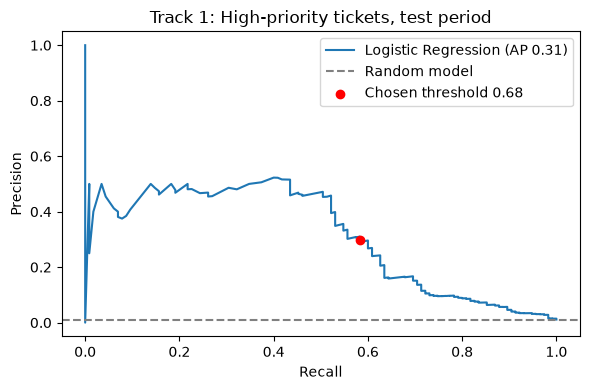

In [15]:
os.makedirs("../reports/figures", exist_ok=True)

pr_p, pr_r, _ = precision_recall_curve(test["High"], p_te)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(pr_r, pr_p, label=f"Logistic Regression (AP {average_precision_score(test['High'], p_te):.2f})")
ax.axhline(test["High"].mean(), color="grey", linestyle="--", label="Random model")
ax.scatter([recall_score(test["High"], pred)], [precision_score(test["High"], pred)],
           color="red", zorder=3, label=f"Chosen threshold {threshold:.2f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Track 1: High-priority tickets, test period")
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/track1_precision_recall.png", dpi=150)
plt.show()

## 16. Coefficient weight by feature group (rough guide)
The sum of absolute coefficients grows with the number of categories, so it is not a true importance score.

In [16]:
grp = {c: coef[coef.index.str.startswith(f"cat__{c}_")] for c in set_b}
print(pd.DataFrame({
    "features": {c: len(v) for c, v in grp.items()},
    "sum |coef|": {c: round(v.abs().sum(), 2) for c, v in grp.items()},
    "max |coef|": {c: round(v.abs().max(), 2) for c, v in grp.items()},
}))
print(grp["CI_Subcat"].sort_values(ascending=False).head(5).round(2))

           features  sum |coef|  max |coef|
CI_Cat           12        2.87        0.65
CI_Subcat        27        6.61        1.64
WBS              99       22.66        1.75
Category          3        1.95        0.97
hour             18        5.15        0.73
weekday           7        2.67        0.71
cat__CI_Subcat_Banking Device        1.64
cat__CI_Subcat_Unknown               0.44
cat__CI_Subcat_Windows Server        0.38
cat__CI_Subcat_infrequent_sklearn    0.38
cat__CI_Subcat_SAN                   0.21
dtype: float64


## 17. Optimisation experiment: rolling-origin comparison
Four monthly folds (December, January, February, 1 to 16 March). Each fold trains on everything before the month. Decisions in this section and the ones after it use these folds, not the test period. Alerts are the top 2.2% of tickets (about 5 a day).

In [17]:
def add_feats(d):
    d = d.copy()
    d["off_hours"] = ((d["hour"] < 8) | (d["hour"] >= 18)).astype(int).astype(str)
    d["is_weekend"] = (d["weekday"] >= 5).astype(int).astype(str)
    d["ci_time"] = d["CI_Cat"] + "|" + d["off_hours"] + d["is_weekend"]
    return d

eng_cols = set_b + ["off_hours", "is_weekend", "ci_time"]
full = add_feats(pd.concat([train, test]).sort_values("Open_Time").reset_index(drop=True))

folds = [("2013-12-01", "2014-01-01"), ("2014-01-01", "2014-02-01"),
         ("2014-02-01", "2014-03-01"), ("2014-03-01", "2014-03-17")]

xgb = lambda d, m: XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=d, min_child_weight=m,
                                 eval_metric="logloss", random_state=42, n_jobs=-1)
cands = {
    "LR, set B (current)": (set_b,    lambda: LogisticRegression(C=0.01, max_iter=2000)),
    "LR + time features":  (eng_cols, lambda: LogisticRegression(C=0.01, max_iter=2000)),
    "XGB + time features": (eng_cols, lambda: xgb(5, 5)),
    "XGB deeper":          (eng_cols, lambda: xgb(7, 10)),
}
ENS = "Average of LR and XGB (rank)"
BUDGET = 0.022   # alert on the top 2.2% of tickets, about 5 a day, like the chosen threshold

ap = {k: [] for k in list(cands) + [ENS]}
rc = {k: [] for k in ap}
for a, b in folds:
    tr = full[full["Open_Time"] < a]
    te = full[(full["Open_Time"] >= a) & (full["Open_Time"] < b)]
    ytr, yte = tr["High"], te["High"].to_numpy()
    w = compute_sample_weight("balanced", ytr)
    probs = {}
    for name, (cols, mk) in cands.items():
        m = make_pipe(cols, mk())
        m.fit(tr[cols].astype(str), ytr, clf__sample_weight=w)
        probs[name] = m.predict_proba(te[cols].astype(str))[:, 1]
    probs[ENS] = (pd.Series(probs["LR + time features"]).rank(pct=True)
                  + pd.Series(probs["XGB + time features"]).rank(pct=True)).to_numpy() / 2
    k = int(np.ceil(BUDGET * len(te)))
    for name, p in probs.items():
        ap[name].append(average_precision_score(yte, p))
        rc[name].append(yte[np.argsort(-p)[:k]].sum() / yte.sum())
    print(f"fold {a} to {b}: tickets {len(te)}, High {int(yte.sum())}, random AP {yte.mean():.4f}")

print(pd.DataFrame({"mean AP": {k: np.mean(v) for k, v in ap.items()},
                    "min AP": {k: np.min(v) for k, v in ap.items()},
                    "mean recall at 2.2% alerts": {k: np.mean(v) for k, v in rc.items()}}).round(3))
print({k: np.round(v, 3).tolist() for k, v in ap.items()})

fold 2013-12-01 to 2014-01-01: tickets 6551, High 130, random AP 0.0198
fold 2014-01-01 to 2014-02-01: tickets 8049, High 100, random AP 0.0124
fold 2014-02-01 to 2014-03-01: tickets 7154, High 79, random AP 0.0110
fold 2014-03-01 to 2014-03-17: tickets 3075, High 36, random AP 0.0117
                              mean AP  min AP  mean recall at 2.2% alerts
LR, set B (current)             0.391   0.274                       0.613
LR + time features              0.392   0.273                       0.614
XGB + time features             0.402   0.300                       0.620
XGB deeper                      0.402   0.291                       0.627
Average of LR and XGB (rank)    0.402   0.281                       0.626
{'LR, set B (current)': [0.51, 0.41, 0.37, 0.274], 'LR + time features': [0.5, 0.421, 0.372, 0.273], 'XGB + time features': [0.466, 0.46, 0.381, 0.3], 'XGB deeper': [0.455, 0.466, 0.397, 0.291], 'Average of LR and XGB (rank)': [0.499, 0.445, 0.382, 0.281]}


## 18. The six unconfirmed-timing fields on the rolling folds

In [18]:
cols_u = set_b + unsure_timing
res = []
for a, b in folds:
    tr = full[full["Open_Time"] < a]
    te = full[(full["Open_Time"] >= a) & (full["Open_Time"] < b)]
    m_six = make_pipe(cols_u, LogisticRegression(C=0.03, max_iter=2000))
    m_six.fit(tr[cols_u].astype(str), tr["High"],
              clf__sample_weight=compute_sample_weight("balanced", tr["High"]))
    res.append(average_precision_score(te["High"], m_six.predict_proba(te[cols_u].astype(str))[:, 1]))
print(np.round(res, 3), "mean", round(np.mean(res), 3))

[0.549 0.503 0.436 0.368] mean 0.464


## 19. Rule baselines and alert budgets
Simple rules against the model at the same alert volume, and the model at fixed alert budgets (share of tickets flagged).

In [19]:
y = test["High"].to_numpy()

def report(name, flag):
    flag = np.asarray(flag).astype(int)
    tp = int(((y == 1) & (flag == 1)).sum())
    print(f"{name}: alerts {flag.sum()} ({flag.mean()*100:.1f}% of tickets), caught {tp}/{int(y.sum())}, "
          f"recall {tp / y.sum():.3f}, precision {tp / max(flag.sum(), 1):.3f}")

def topk_flag(scores, share):
    k = int(round(share * len(scores)))
    flag = np.zeros(len(scores), dtype=int)
    flag[np.argsort(-scores)[:k]] = 1
    return flag

is_comp = (test["CI_Cat"] == "computer").to_numpy()
is_inc = (test["Category"] == "incident").to_numpy()
report("Rule: computer tickets", is_comp)
report("Rule: computer and incident", is_comp & is_inc)
report("Model at chosen threshold", pred)
report("Model, same volume as the computer rule", topk_flag(p_te, is_comp.mean()))
report("Model, same volume as computer and incident", topk_flag(p_te, (is_comp & is_inc).mean()))
for share in [0.01, 0.022, 0.05, 0.10]:
    report(f"Model, top {share * 100:.1f}% of tickets", topk_flag(p_te, share))

Rule: computer tickets: alerts 765 (7.5% of tickets), caught 62/115, recall 0.539, precision 0.081
Rule: computer and incident: alerts 742 (7.3% of tickets), caught 62/115, recall 0.539, precision 0.084
Model at chosen threshold: alerts 225 (2.2% of tickets), caught 67/115, recall 0.583, precision 0.298
Model, same volume as the computer rule: alerts 765 (7.5% of tickets), caught 83/115, recall 0.722, precision 0.108
Model, same volume as computer and incident: alerts 742 (7.3% of tickets), caught 83/115, recall 0.722, precision 0.112
Model, top 1.0% of tickets: alerts 102 (1.0% of tickets), caught 50/115, recall 0.435, precision 0.490
Model, top 2.2% of tickets: alerts 225 (2.2% of tickets), caught 67/115, recall 0.583, precision 0.298
Model, top 5.0% of tickets: alerts 511 (5.0% of tickets), caught 80/115, recall 0.696, precision 0.157
Model, top 10.0% of tickets: alerts 1023 (10.0% of tickets), caught 92/115, recall 0.800, precision 0.090


## 20. Performance by segment: asset, time of day and category

In [20]:
sl = test.assign(flag=pred, y=y)
sl["asset"] = np.where(sl["CI_Cat"] == "computer", "computer", "other assets")
sl["when"] = np.where(sl["hour"].between(4, 7) | (sl["weekday"] >= 5), "night/weekend", "normal hours")
for col in ["asset", "when", "Category"]:
    g = sl.groupby(col).agg(tickets=("y", "size"), High=("y", "sum"), alerts=("flag", "sum"))
    g["caught"] = sl[sl["y"] == 1].groupby(col)["flag"].sum()
    g = g.fillna(0)
    g["recall"] = (g["caught"] / g["High"].replace(0, np.nan)).round(2)
    print(g, "\n")

              tickets  High  alerts  caught  recall
asset                                              
computer          765    62     153      60    0.97
other assets     9464    53      72       7    0.13 

               tickets  High  alerts  caught  recall
when                                                
night/weekend      178     7      45       3    0.43
normal hours     10051   108     180      64    0.59 

                         tickets  High  alerts  caught  recall
Category                                                      
complaint                      3     0       0     0.0     NaN
incident                    8530   114     218    67.0    0.59
request for information     1696     1       7     0.0    0.00 



## 21. Why recall fell from 0.70 (validation) to 0.58 (test): diagnostics
Does refitting on October to January change recall, and does recall differ between February and early March?

In [21]:
m_octdec = clone(fit_b[best_name].best_estimator_)
m_octdec.fit(fit_part[set_b].astype(str), fit_part["High"],
             clf__sample_weight=compute_sample_weight("balanced", fit_part["High"]))
p_m = m_octdec.predict_proba(test[set_b].astype(str))[:, 1]
pred_m = (p_m >= threshold).astype(int)
yt = test["High"].to_numpy()

tp_m = int(((yt == 1) & (pred_m == 1)).sum())
print("Oct-Dec model on test: alerts", int(pred_m.sum()), "| caught", tp_m, "of", int(yt.sum()), "| recall", round(tp_m / yt.sum(), 3))
tp_f = int(((yt == 1) & (pred == 1)).sum())
print("Final model on test   : alerts", int(pred.sum()), "| caught", tp_f, "of", int(yt.sum()), "| recall", round(tp_f / yt.sum(), 3))

for name, mask in [("Feb", test["Open_Time"] < "2014-03-01"), ("Mar 1-16", test["Open_Time"] >= "2014-03-01")]:
    mk = mask.to_numpy()
    tp = int(((yt[mk] == 1) & (pred[mk] == 1)).sum())
    print(name, "| High", int(yt[mk].sum()), "| caught", tp, "| recall", round(tp / yt[mk].sum(), 3), "| alerts", int(pred[mk].sum()))

Oct-Dec model on test: alerts 224 | caught 66 of 115 | recall 0.574
Final model on test   : alerts 225 | caught 67 of 115 | recall 0.583
Feb | High 79 | caught 45 | recall 0.57 | alerts 143
Mar 1-16 | High 36 | caught 22 | recall 0.611 | alerts 82


## 22. Computer share of High tickets by month

In [22]:
allx = pd.concat([train, test])
h = allx[allx["High"] == 1].copy()
h["computer"] = h["CI_Cat"] == "computer"
print(h.groupby(h["Open_Time"].dt.to_period("M"))["computer"].agg(["size", "sum", "mean"]).round(2))

           size  sum  mean
Open_Time                 
2013-10     178  107  0.60
2013-11     133   81  0.61
2013-12     130   92  0.71
2014-01     100   65  0.65
2014-02      79   42  0.53
2014-03      36   20  0.56


## 23. The six fields at equal alert volume (225 alerts), by asset segment

In [23]:
cols_u = set_b + unsure_timing
gs_u = tune_lr(cols_u)
p_u = gs_u.best_estimator_.predict_proba(test[cols_u].astype(str))[:, 1]
flag_u = topk_flag(p_u, 225 / len(test))
seg = np.where(test["CI_Cat"] == "computer", "computer", "other assets")
for s in ["computer", "other assets"]:
    mk = seg == s
    print(s, "| High", int(yt[mk].sum()), "| caught", int(((yt[mk] == 1) & (flag_u[mk] == 1)).sum()))

computer | High 62 | caught 60
other assets | High 53 | caught 19


## Appendix A. History features (not adopted)
Prior-ticket features for the same CI or WBS (recent ticket counts, smoothed prior High rate), tested on the rolling folds. The gains were within noise (see data_issues_log.md).

### A1. Build the features

In [24]:
full2 = full.copy()
for c in set_b:
    full2[c] = full2[c].astype(str)
tt = full2["Open_Time"].to_numpy()

def prior_count(key, hours):
    out = np.zeros(len(full2))
    for idx in full2.groupby(key).indices.values():
        t = tt[idx]
        left = np.searchsorted(t, t - np.timedelta64(hours, "h"), side="left")
        out[idx] = np.arange(len(idx)) - left
    return out

def prior_high_rate(key, a=20):
    g = full2.groupby(key)["High"]
    n_prior = g.cumcount()
    h_prior = g.cumsum() - full2["High"]
    base = full2["High"].expanding().mean().shift(1).fillna(full2["High"].mean())
    return ((h_prior + a * base) / (n_prior + a)).to_numpy()

full2["ci_n_7d"] = np.log1p(prior_count("CI_Name", 24 * 7))
full2["wbs_n_24h"] = np.log1p(prior_count("WBS", 24))
full2["ci_high_rate"] = prior_high_rate("CI_Name")
full2["wbs_high_rate"] = prior_high_rate("WBS")
print(full2[["ci_n_7d", "wbs_n_24h", "ci_high_rate", "wbs_high_rate"]].describe().round(3).loc[["mean", "min", "max"]])

      ci_n_7d  wbs_n_24h  ci_high_rate  wbs_high_rate
mean    2.668      2.482         0.010          0.017
min     0.000      0.000         0.000          0.000
max     5.242      5.521         0.305          0.510


### A2. Rolling-fold comparison

In [25]:
def make2(cat_cols, num_cols, C=0.01):
    enc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30)
    parts = [("cat", enc, cat_cols)]
    if num_cols:
        parts.append(("num", StandardScaler(), num_cols))
    return Pipeline([("pre", ColumnTransformer(parts)), ("clf", LogisticRegression(C=C, max_iter=3000))])

def roll(num_cols):
    aps, rcs, rco, apo = [], [], [], []
    cols = set_b + num_cols
    for a, b in folds:
        tr = full2[full2["Open_Time"] < a]
        te = full2[(full2["Open_Time"] >= a) & (full2["Open_Time"] < b)]
        m = make2(set_b, num_cols)
        m.fit(tr[cols], tr["High"], clf__sample_weight=compute_sample_weight("balanced", tr["High"]))
        p = m.predict_proba(te[cols])[:, 1]
        y_ = te["High"].to_numpy()
        oth = (te["CI_Cat"] != "computer").to_numpy()
        flag = np.zeros(len(te), dtype=bool)
        flag[np.argsort(-p)[:int(np.ceil(0.022 * len(te)))]] = True
        aps.append(average_precision_score(y_, p))
        rcs.append(y_[flag].sum() / y_.sum())
        rco.append(y_[flag & oth].sum() / max(y_[oth].sum(), 1))
        apo.append(average_precision_score(y_[oth], p[oth]))
    return [float(np.mean(v)) for v in (aps, rcs, rco, apo)], np.round(aps, 3).tolist()

variants = {
    "Set B (should reproduce 0.391 / 0.613)": [],
    "+ recent tickets on same CI / WBS": ["ci_n_7d", "wbs_n_24h"],
    "+ prior High rate of CI / WBS": ["ci_high_rate", "wbs_high_rate"],
    "+ both": ["ci_n_7d", "wbs_n_24h", "ci_high_rate", "wbs_high_rate"],
}
res = {k: roll(v) for k, v in variants.items()}
print(pd.DataFrame({k: v[0] for k, v in res.items()},
                   index=["mean AP", "recall at 2.2% alerts", "recall, non-computer", "AP, non-computer"]).T.round(3))
print({k: v[1] for k, v in res.items()})

                                        mean AP  recall at 2.2% alerts  \
Set B (should reproduce 0.391 / 0.613)    0.391                  0.613   
+ recent tickets on same CI / WBS         0.389                  0.623   
+ prior High rate of CI / WBS             0.414                  0.651   
+ both                                    0.416                  0.656   

                                        recall, non-computer  AP, non-computer  
Set B (should reproduce 0.391 / 0.613)                 0.072             0.063  
+ recent tickets on same CI / WBS                      0.107             0.067  
+ prior High rate of CI / WBS                          0.183             0.142  
+ both                                                 0.190             0.142  
{'Set B (should reproduce 0.391 / 0.613)': [0.51, 0.41, 0.37, 0.274], '+ recent tickets on same CI / WBS': [0.533, 0.409, 0.339, 0.274], '+ prior High rate of CI / WBS': [0.508, 0.446, 0.331, 0.374], '+ both': [0.514, 0.45, 